In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

print("Missing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Duplicate rows: 0


In [3]:

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

# Remove customer ID (not useful for prediction)
df = df.drop(columns=["customerID"])

print("\nCleaned dataset shape:", df.shape)


Missing values:
TotalCharges    11
dtype: int64

Cleaned dataset shape: (7032, 20)


Churn distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn rate: 26.58%


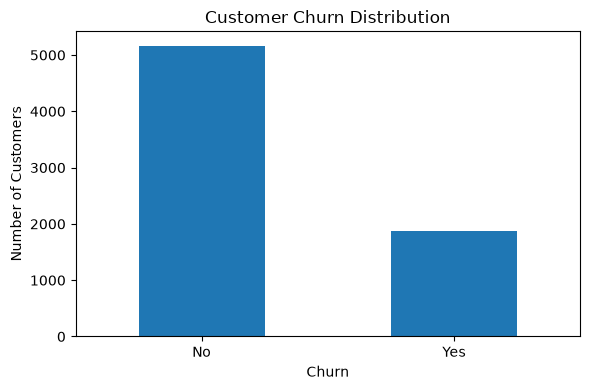

In [4]:

churn_counts = df["Churn"].value_counts()

churn_rate = (
    df["Churn"].eq("Yes").mean() * 100
)

print("Churn distribution:")
print(churn_counts)

print(f"\nChurn rate: {churn_rate:.2f}%")

plt.figure(figsize=(6, 4))
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Feature Engineering & Data Preparation

We prepare the dataset for machine learning by separating the target variable, encoding categorical features, and splitting the data into training and testing sets. Preprocessing is fitted only on the training data to prevent data leakage.

In [5]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Identify feature types
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))


Training set: (5625, 19)
Test set: (1407, 19)
Categorical features: 15
Numerical features: 4


## 6. Baseline Model: Logistic Regression

Logistic Regression is used as an interpretable baseline
for predicting customer churn. The preprocessing and
classification steps are combined into a single pipeline.

In [6]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Build baseline pipeline
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train model
baseline_model.fit(X_train, y_train)

# Generate predictions
y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.8038
Precision: 0.6485
Recall: 0.5722
F1 Score: 0.608
ROC-AUC: 0.8359

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



## 8. XGBoost Model Training

We train an XGBoost classifier to capture non-linear
relationships between customer features and churn.

The model is evaluated on the same test dataset
as Logistic Regression for a fair comparison.

In [7]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

# Build XGBoost pipeline
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train XGBoost
xgb_model.fit(X_train, y_train)

# Predictions
xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("XGBoost Results")
print("Accuracy:", round(accuracy_score(y_test, xgb_pred), 4))
print("Precision:", round(precision_score(y_test, xgb_pred), 4))
print("Recall:", round(recall_score(y_test, xgb_pred), 4))
print("F1 Score:", round(f1_score(y_test, xgb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, xgb_proba), 4))


XGBoost Results
Accuracy: 0.7946
Precision: 0.6375
Recall: 0.5267
F1 Score: 0.5769
ROC-AUC: 0.8386


## 9. Model Comparison

We compare Logistic Regression and XGBoost using
Accuracy, Precision, Recall, F1 Score, and ROC-AUC
to identify their strengths and limitations.

In [8]:

import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba)
    ],
    "XGBoost": [
        accuracy_score(y_test, xgb_pred),
        precision_score(y_test, xgb_pred),
        recall_score(y_test, xgb_pred),
        f1_score(y_test, xgb_pred),
        roc_auc_score(y_test, xgb_proba)
    ]
})

display(results.round(4))


,Metric,Logistic Regression,XGBoost
0,Accuracy,0.8038,0.7946
1,Precision,0.6485,0.6375
2,Recall,0.5722,0.5267
3,F1 Score,0.6080,0.5769
4,ROC-AUC,0.8359,0.8386


## 10. Cross-Validation

We evaluate both models using stratified 5-fold
cross-validation on the training data.

This helps assess model stability and compare
their generalization performance without
further relying on the test set.

In [9]:

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision"
}

models = {
    "Logistic Regression": baseline_model,
    "XGBoost": xgb_model
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "F1": scores["test_f1"].mean(),
        "Recall": scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(4))


,Model,ROC-AUC,F1,Recall,Precision,ROC-AUC Std
0,Logistic Regression,0.8461,0.5953,0.5465,0.6541,0.0052
1,XGBoost,0.8491,0.5906,0.5278,0.6712,0.0035


In [10]:

# Style the cross-validation results
styled_cv = (
    cv_df.style
    .format({
        "ROC-AUC": "{:.4f}",
        "F1": "{:.4f}",
        "Recall": "{:.4f}",
        "Precision": "{:.4f}",
        "ROC-AUC Std": "{:.4f}"
    })
    .background_gradient(
        cmap="Blues",
        subset=["ROC-AUC", "F1", "Recall", "Precision"]
    )
    .set_caption("5-Fold Cross-Validation Results")
)

display(styled_cv)


,Model,ROC-AUC,F1,Recall,Precision,ROC-AUC Std
0,Logistic Regression,0.8461,0.5953,0.5465,0.6541,0.0052
1,XGBoost,0.8491,0.5906,0.5278,0.6712,0.0035


## 11. Final Model Evaluation

Logistic Regression was selected as the preferred baseline
based on its simplicity, interpretability, and slightly
higher cross-validation recall and F1 score.

The following evaluation summarizes its performance
on the previously examined test set.

Final Model: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



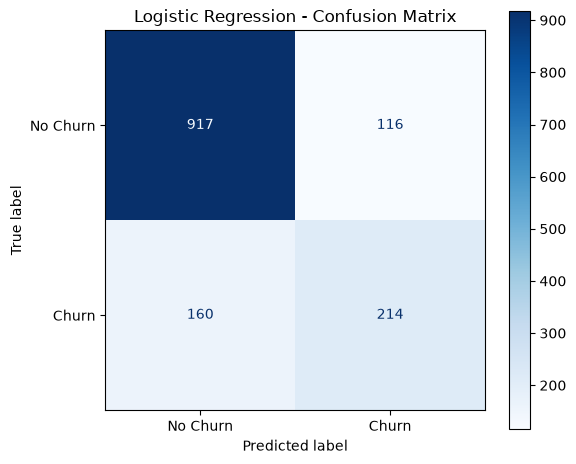

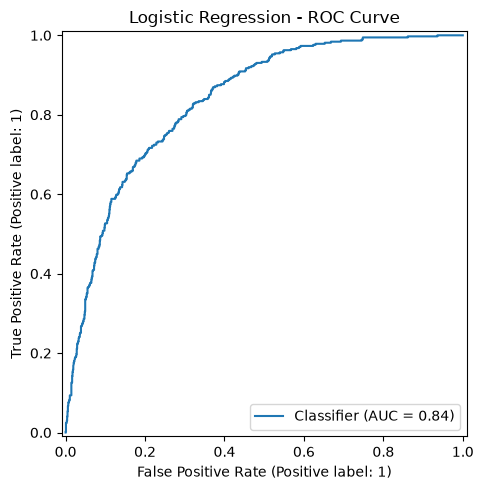

In [11]:

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Summarize the selected model's test performance
print("Final Model: Logistic Regression")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# ROC curve
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    ax=ax
)

ax.set_title("Logistic Regression - ROC Curve")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()


## 12. Business Insights & Conclusion

### Key Findings

- Contract type is associated with customer churn.
- Logistic Regression provides a competitive and
  interpretable baseline for churn prediction.
- XGBoost achieved a slightly higher cross-validation
  ROC-AUC, while Logistic Regression achieved
  slightly higher recall and F1 scores.
- The model can help prioritize customers for
  retention analysis.

### Limitations

- The dataset represents a fictional telecom company.
- Model performance may differ on real-world data.
- Predictions indicate churn risk, not causal effects.
- Business impact requires further validation.

### Future Improvements

- Hyperparameter tuning using cross-validation.
- Decision threshold optimization.
- Probability calibration.
- Model deployment using Streamlit or FastAPI.